# Lab 2. Why random splits flatter your map

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yunusserhat/eo-gis-practicals/blob/main/notebooks/lab2_why_random_splits_flatter_your_map.ipynb)

In Lab 1 you trained a classifier and tested it on a random 30% of your training pixels. The accuracy looked
excellent. In this practical you will find out how much of that accuracy is real.

Nearby places tend to look alike. This is spatial autocorrelation, and it means that a test pixel next to a training
pixel is not a fair test. The lab follows the validation design of Bıçakçı (2026), *Photogrammetric Engineering &
Remote Sensing*, in press, where test areas were locked away in spatial blocks before any model was fitted. In that
study a random split would have lifted a model that used no satellite data at all from R² 0.03 to 0.32.

**Learning outcomes.** By the end of the lab you should be able to
1. explain why spatial autocorrelation breaks the independence that a random test set assumes,
2. run grouped and spatially blocked cross-validation with square grid blocks and H3 hexagons,
3. interpret the gap between random and spatial accuracy estimates,
4. test whether errors cluster in space with Moran's I.

**Level and time.** Honours (SCQF level 10) or MSc (SCQF level 11), about two hours. The lab reuses the training
pixels from Lab 1. If you have not run Lab 1 in this session, for example on Google Colab, the first code cells
download the saved Lab 1 outputs from the repository.

**Running on Google Colab?** The next cell installs the few packages that Colab lacks, which takes about a minute.
On your own computer it does nothing.

In [1]:
# Copyright (C) 2026 Yunus Serhat Bıçakçı
# SPDX-License-Identifier: GPL-3.0-or-later
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "libpysal", "esda", "h3", "pyogrio"], check=True)

In [2]:
import os
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import h3
import matplotlib.pyplot as plt
from pyproj import Transformer
from shapely.geometry import Polygon
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict, train_test_split
from sklearn.metrics import accuracy_score, f1_score
from libpysal.weights import KNN
from esda.moran import Moran

warnings.filterwarnings("ignore", category=FutureWarning)
# Within each 5 by 5 square, a pixel's nearest neighbours all lie in the same square. libpysal warns that the
# neighbour graph falls apart into one piece per square. That is the point of section 2, so the warning is silenced.
warnings.filterwarnings("ignore", message="The weights matrix is not fully connected")
ROOT = Path.cwd() if IN_COLAB else Path("..")  # on Colab, files go into the session folder
DATA = ROOT / "data"
FIGURES = ROOT / "figures"
DATA.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
FEATURES = ["B02", "B03", "B04", "B08", "B11", "B12", "NDVI", "NDBI", "MNDWI", "VV_dB", "VH_dB"]
CLASSES = {1: "sealed", 2: "green", 3: "water"}

# Without a local Lab 1 run, for example on Colab, fetch the saved Lab 1 outputs from the repository.
LAB1_OUTPUTS = "https://raw.githubusercontent.com/yunusserhat/eo-gis-practicals/main/lab1_outputs/"
for name in ["lab1_training_pixels.csv", "training_polygons.gpkg"]:
    if not (DATA / name).exists():
        print(f"{name} not found locally, downloading the saved Lab 1 output")
        urllib.request.urlretrieve(LAB1_OUTPUTS + name, DATA / name)

train = pd.read_csv(DATA / "lab1_training_pixels.csv")
polygons = gpd.read_file(DATA / "training_polygons.gpkg", layer="training_polygons")
X = train[FEATURES].values
XY = train[["E", "N"]].values
y = train["label"].values
print(f"{len(train)} training pixels in {train.polygon_id.nunique()} squares")

forest = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)

def evaluate(features, cv, groups=None):
    """Cross-validated overall accuracy and macro F1 for one feature set and one splitting scheme."""
    predicted = cross_val_predict(forest, features, y, cv=cv, groups=groups)
    return accuracy_score(y, predicted), f1_score(y, predicted, average="macro"), predicted

def blocks(size_m):
    """Label each pixel with the square block of the given size that contains it."""
    return (train.E // size_m).astype(int).astype(str) + "_" + (train.N // size_m).astype(int).astype(str)

TO_LONLAT = Transformer.from_crs("EPSG:27700", "EPSG:4326", always_xy=True)
train["lon"], train["lat"] = TO_LONLAT.transform(train.E.values, train.N.values)

def hexagons(resolution):
    """Label each pixel with the H3 hexagon of the given resolution that contains it."""
    return np.array([h3.latlng_to_cell(lat, lon, resolution) for lat, lon in zip(train.lat, train.lon)])

3340 training pixels in 140 squares


## 1. The Lab 1 result again

First we repeat the random 70 and 30 split from Lab 1, so that we have the number to beat.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
random_split = accuracy_score(y_test, forest.fit(X_train, y_train).predict(X_test))
print(f"Random 30% test set, overall accuracy {random_split:.3f}")

Random 30% test set, overall accuracy 0.977


## 2. How alike are neighbouring pixels?

Moran's I measures whether values at nearby locations are more similar than chance. It runs from about minus 1
(neighbours differ) through 0 (no pattern) to plus 1 (neighbours are alike). We compute it for NDVI at the training
pixels, with each pixel's eight nearest pixels as its neighbours.

**Predict.** Will Moran's I for NDVI be close to 0, or close to 1?

In [4]:
weights = KNN.from_array(XY, k=8)
weights.transform = "r"
np.random.seed(42)  # fixes the permutations, so the pseudo p-value is the same on every run
moran_ndvi = Moran(train["NDVI"].values, weights, permutations=999)
print(f"Moran's I for NDVI {moran_ndvi.I:.2f}, pseudo p-value {moran_ndvi.p_sim:.3f}")

Moran's I for NDVI 0.94, pseudo p-value 0.001


**Investigate.** Each pixel's eight nearest neighbours sit inside its own 50 m square. A value this high means that
most test pixels in Lab 1 had a near copy in the training set. The model could pass the test by recognising places
it had already seen.

## 3. Fairer tests. Hold out whole squares, blocks or hexagons

We now use five-fold cross-validation in four ways.
- **Random pixels.** Any pixel can be in any fold, as in Lab 1.
- **By square.** All pixels of a training square stay in the same fold, so the model is always tested on squares it
  has never seen.
- **1 km blocks.** All pixels in the same 1 by 1 km block of the National Grid stay together, so the test areas are
  also some distance from the training areas.
- **H3 hexagons.** All pixels in the same hexagon of the H3 grid stay together. H3 is a hierarchical grid of
  hexagons that covers the whole globe. Every hexagon has six neighbours at the same distance from its centre, and
  each finer resolution splits a hexagon into about seven smaller ones. At resolution 8 a hexagon covers on average
  0.74 km², close to the area of a 1 km grid square.

**Predict.** Rank the four schemes from highest to lowest accuracy. Will squares and hexagons of similar size agree?

In [5]:
print(f"Average H3 hexagon at resolution 8 {h3.average_hexagon_area(8, unit='km^2'):.2f} km²")
schemes = {
    "random pixels": (KFold(5, shuffle=True, random_state=42), None),
    "by square": (GroupKFold(5), train["polygon_id"].values),
    "1 km blocks": (GroupKFold(5), blocks(1000).values),
    "H3 hexagons, res. 8": (GroupKFold(5), hexagons(8)),
}
results = []
for name, (cv, groups) in schemes.items():
    accuracy, macro_f1, _ = evaluate(X, cv, groups)
    results.append({"model": "Sentinel-1 and Sentinel-2", "scheme": name,
                    "overall accuracy": round(accuracy, 3), "macro F1": round(macro_f1, 3)})
pd.DataFrame(results)

Average H3 hexagon at resolution 8 0.74 km²


,model,scheme,overall accuracy,macro F1
0,Sentinel-1 and Sentinel-2,random pixels,0.981,0.984
1,Sentinel-1 and Sentinel-2,by square,0.963,0.963
2,Sentinel-1 and Sentinel-2,1 km blocks,0.957,0.957
3,Sentinel-1 and Sentinel-2,"H3 hexagons, res. 8",0.958,0.957


The map below shows the resolution 8 hexagons that contain training squares, coloured by the fold in which they are
held out. Every pixel in a hexagon is tested together, by a model trained on the other four folds.

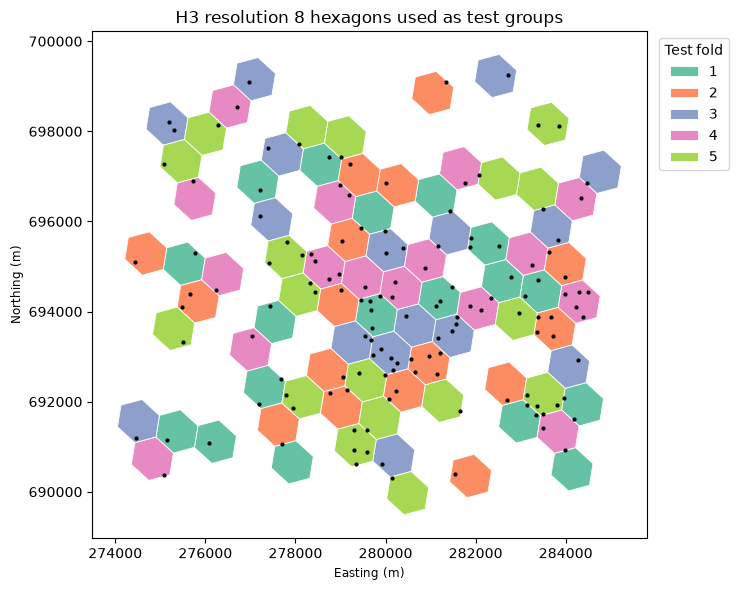

84 hexagons hold the 140 training squares


In [6]:
h3_groups = hexagons(8)
fold = np.empty(len(train), dtype=int)
for k, (_, test_index) in enumerate(GroupKFold(5).split(X, y, h3_groups)):
    fold[test_index] = k + 1
cells = pd.DataFrame({"cell": h3_groups, "fold": fold}).drop_duplicates("cell")
hex_polygons = gpd.GeoDataFrame(
    cells,
    geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(cell)]) for cell in cells.cell],
    crs="EPSG:4326",
).to_crs("EPSG:27700")

fig, ax = plt.subplots(figsize=(8.5, 6))
hex_polygons.plot(ax=ax, column="fold", categorical=True, cmap="Set2", edgecolor="white", linewidth=0.6,
                  legend=True, legend_kwds={"title": "Test fold", "loc": "upper left", "bbox_to_anchor": (1.01, 1)})
ax.scatter(polygons.geometry.centroid.x, polygons.geometry.centroid.y, s=4, color="black", label="training squares")
ax.set_title("H3 resolution 8 hexagons used as test groups")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
plt.tight_layout()
plt.savefig(FIGURES / "lab2_h3_folds.png", dpi=120)
plt.show()
print(f"{len(cells)} hexagons hold the {len(polygons)} training squares")

## 4. A model that never sees the satellite

Now a thought experiment. We train the same random forest on nothing but the easting and northing of each pixel.
This model knows where a pixel is and nothing about what the satellite saw there.

**Predict.** How accurate will this model be under each scheme? Write down three numbers.

In [7]:
for name, (cv, groups) in schemes.items():
    accuracy, macro_f1, _ = evaluate(XY, cv, groups)
    results.append({"model": "coordinates only", "scheme": name,
                    "overall accuracy": round(accuracy, 3), "macro F1": round(macro_f1, 3)})
table = pd.DataFrame(results)
table

,model,scheme,overall accuracy,macro F1
0,Sentinel-1 and Sentinel-2,random pixels,0.981,0.984
1,Sentinel-1 and Sentinel-2,by square,0.963,0.963
2,Sentinel-1 and Sentinel-2,1 km blocks,0.957,0.957
3,Sentinel-1 and Sentinel-2,"H3 hexagons, res. 8",0.958,0.957
4,coordinates only,random pixels,1.000,1.000
5,coordinates only,by square,0.631,0.594
6,coordinates only,1 km blocks,0.604,0.578
7,coordinates only,"H3 hexagons, res. 8",0.653,0.623


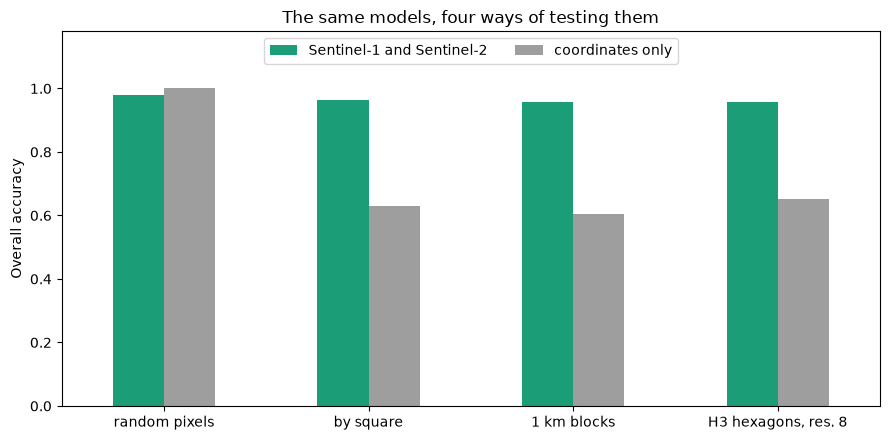

In [8]:
MODEL_COLOURS = {"Sentinel-1 and Sentinel-2": "#1b9e77", "coordinates only": "#9e9e9e"}
pivot = table.pivot(index="scheme", columns="model", values="overall accuracy").loc[list(schemes), list(MODEL_COLOURS)]
ax = pivot.plot.bar(figsize=(9, 4.5), color=MODEL_COLOURS, rot=0)
ax.set_xlabel("")
ax.set_ylabel("Overall accuracy")
ax.set_ylim(0, 1.18)
ax.set_title("The same models, four ways of testing them")
ax.legend(title="", loc="upper center", ncol=2)
plt.tight_layout()
plt.savefig(FIGURES / "lab2_validation_schemes.png", dpi=120)
plt.show()

**Investigate.**
1. Under random pixels the coordinates-only model looks as good as, or better than, the satellite model. Why?
2. What happens to it once whole squares, blocks or hexagons are held out?
3. Did 1 km squares and resolution 8 hexagons, which are close in size, give similar results?
4. Which of the numbers in the table would you report in a paper, and why?

## 5. Does the block size matter?

Bigger blocks push test areas further from training areas. We repeat the blocked test with square blocks from 250 m
to 4 km and with H3 hexagons from resolution 10 to resolution 6. For hexagons the width shown is the square root of
the average hexagon area, so both grids can share one axis.

**Predict.** Sketch how each model's accuracy will change as the blocks grow. Will the hexagon curves follow the
square ones?

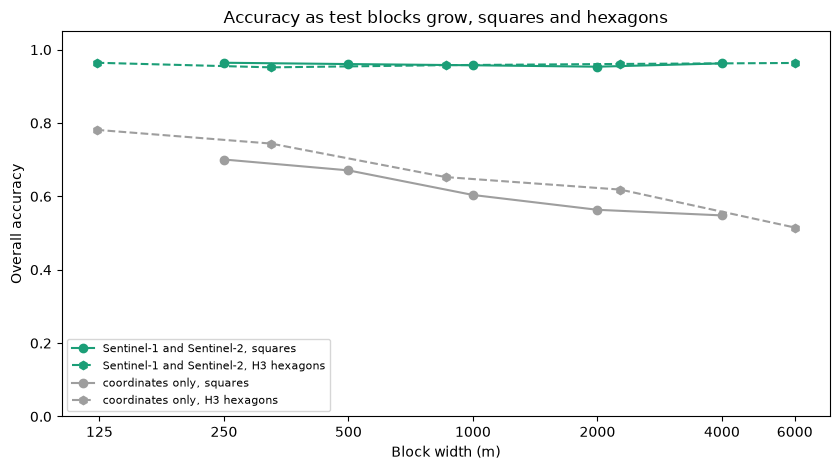

model                  Sentinel-1 and Sentinel-2  coordinates only
grid        width (m)                                             
H3 hexagons 123                            0.964             0.781
            325                            0.952             0.744
            859                            0.958             0.653
            2272                           0.961             0.619
            6011                           0.964             0.515
squares     250                            0.964             0.701
            500                            0.961             0.671
            1000                           0.957             0.604
            2000                           0.954             0.563
            4000                           0.963             0.548

In [9]:
sizes = [250, 500, 1000, 2000, 4000]
resolutions = [10, 9, 8, 7, 6]
curve = []
for model, features in [("Sentinel-1 and Sentinel-2", X), ("coordinates only", XY)]:
    for size in sizes:
        accuracy, _, _ = evaluate(features, GroupKFold(5), blocks(size).values)
        curve.append({"grid": "squares", "width (m)": size, "model": model, "overall accuracy": accuracy})
    for resolution in resolutions:
        width = round(np.sqrt(h3.average_hexagon_area(resolution, unit="m^2")))
        accuracy, _, _ = evaluate(features, GroupKFold(5), hexagons(resolution))
        curve.append({"grid": "H3 hexagons", "width (m)": width, "model": model, "overall accuracy": accuracy})
curve = pd.DataFrame(curve)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for model, colour in MODEL_COLOURS.items():
    for grid, style, marker in [("squares", "-", "o"), ("H3 hexagons", "--", "h")]:
        part = curve[(curve.model == model) & (curve.grid == grid)].sort_values("width (m)")
        ax.plot(part["width (m)"], part["overall accuracy"], linestyle=style, marker=marker, color=colour,
                label=f"{model}, {grid}")
ax.set_xscale("log")
ax.minorticks_off()
ticks = [125, 250, 500, 1000, 2000, 4000, 6000]
ax.set_xticks(ticks)
ax.set_xticklabels([str(t) for t in ticks])
ax.set_xlabel("Block width (m)")
ax.set_ylabel("Overall accuracy")
ax.set_ylim(0, 1.05)
ax.legend(fontsize=8, loc="lower left")
ax.set_title("Accuracy as test blocks grow, squares and hexagons")
plt.tight_layout()
plt.savefig(FIGURES / "lab2_block_size.png", dpi=120)
plt.show()
curve.pivot_table(index=["grid", "width (m)"], columns="model", values="overall accuracy").round(3)

## 6. Where are the errors?

Finally we look at the errors of the satellite model under the 1 km block test. For each training square we compute
the share of its pixels that were misclassified, map it and ask whether squares with errors sit near each other.

**Predict.** Will the errors be scattered at random, or clustered in particular parts of the study area?

Squares with at least one error 32 of 140
Moran's I for square error rates 0.05, pseudo p-value 0.088


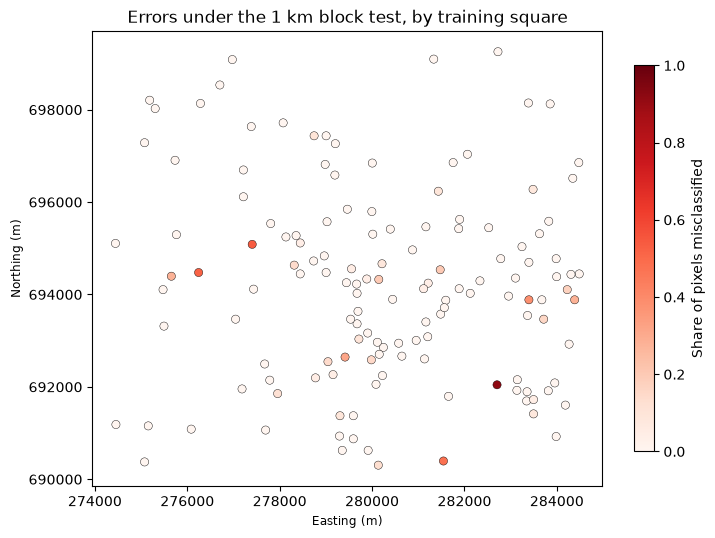

,mean error rate
class,
green,0.061
sealed,0.029
water,0.034


In [10]:
_, _, block_predicted = evaluate(X, GroupKFold(5), blocks(1000).values)
train["error"] = (block_predicted != y).astype(int)
per_square = train.groupby("polygon_id")["error"].mean().rename("error_rate")
squares = polygons.merge(per_square, on="polygon_id")
squares["centroid"] = squares.geometry.centroid
centroid_xy = np.c_[squares.centroid.x, squares.centroid.y]
w_squares = KNN.from_array(centroid_xy, k=6)
w_squares.transform = "r"
np.random.seed(42)
moran_errors = Moran(squares["error_rate"].values, w_squares, permutations=999)
print(f"Squares with at least one error {int((squares.error_rate > 0).sum())} of {len(squares)}")
print(f"Moran's I for square error rates {moran_errors.I:.2f}, pseudo p-value {moran_errors.p_sim:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 6))
squares.set_geometry("centroid").plot(ax=ax, column="error_rate", cmap="Reds", legend=True, markersize=35,
                                      edgecolor="black", linewidth=0.3, vmin=0, vmax=1,
                                      legend_kwds={"label": "Share of pixels misclassified", "shrink": 0.7})
ax.set_title("Errors under the 1 km block test, by training square")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
plt.tight_layout()
plt.show()
squares.groupby("class")["error_rate"].mean().round(3).to_frame("mean error rate")

**Investigate.** Which class carries most of the errors? If Moran's I is not significant, the errors are not
clustered at this scale. What would a significant positive value have told you about where to collect more training
data?

## 7. Optional extension. AlphaEarth satellite embeddings

Google DeepMind's AlphaEarth Foundations model summarises a year of satellite observations as 64 numbers for every
10 m pixel. In Bıçakçı (2026) these embeddings matched standard Sentinel-2 products for street greenery. Here you can
test whether they classify Stirling's surfaces better than the bands and indices from Lab 1, under the fair 1 km
block test.

This section needs a free Google Earth Engine account and a Cloud project. Set the environment variable
`EE_PROJECT` to your project before starting Jupyter. On Colab, run `os.environ["EE_PROJECT"] = "your-project"` in
a new cell first, and Colab will ask you to authorise Earth Engine. Without a project the section is skipped.

In [11]:
EE_PROJECT = os.environ.get("EE_PROJECT")
if not EE_PROJECT:
    print("Optional extension skipped. Set EE_PROJECT to run it.")
else:
    import ee

    if IN_COLAB:
        ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)
    lon, lat = train.lon.values, train.lat.values
    embedding = (ee.ImageCollection("GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL")
                 .filterDate("2025-01-01", "2026-01-01").mosaic())
    bands = [f"A{i:02d}" for i in range(64)]
    samples = []
    for start in range(0, len(train), 1000):
        chunk = ee.FeatureCollection([
            ee.Feature(ee.Geometry.Point([float(lon[i]), float(lat[i])]), {"pixel": int(i)})
            for i in range(start, min(start + 1000, len(train)))
        ])
        info = embedding.sampleRegions(collection=chunk, scale=10, geometries=False).getInfo()
        samples.extend(feature["properties"] for feature in info["features"])
    emb = pd.DataFrame(samples).set_index("pixel").sort_index()
    keep = emb.index.values
    X_emb = emb[bands].values
    groups = blocks(1000).values[keep]
    comparison = []
    for name, features in [("Sentinel bands and indices", X[keep]), ("AlphaEarth embeddings", X_emb),
                           ("both together", np.c_[X[keep], X_emb])]:
        predicted = cross_val_predict(forest, features, y[keep], cv=GroupKFold(5), groups=groups)
        comparison.append({"features": name,
                           "overall accuracy": round(accuracy_score(y[keep], predicted), 3),
                           "macro F1": round(f1_score(y[keep], predicted, average="macro"), 3)})
    print(f"Embeddings found for {len(keep)} of {len(train)} pixels")
    display(pd.DataFrame(comparison))

Embeddings found for 3340 of 3340 pixels


,features,overall accuracy,macro F1
0,Sentinel bands and indices,0.957,0.957
1,AlphaEarth embeddings,0.980,0.980
2,both together,0.981,0.982


## 8. Make and reflect

**Make.** Rerun Labs 1 and 2 for your own town from the assessment brief, and report both the random split and the
1 km block result.

**Reflect.**
1. In your own words, why does a random split flatter a map?
2. Our labels and our images both come from Sentinel data. Could a model score well against WorldCover and still be
   wrong on the ground? How would you check?
3. A planning officer wants a map of sealed surfaces for a town 50 km away. Which accuracy figure from this lab would
   you give them, and what would you add to it?
4. Squares follow the National Grid, while H3 hexagons cover the whole globe in one system. Which would you choose
   for a study that spans several countries, and why?